# Control cinemático · corregir el error de posición

[Explicación completa y diagramas](README.md) · [Mapa de estudio](../README.md)

Notebook autocontenido: se ejecuta de arriba hacia abajo y no importa funciones de `code/`. Las ecuaciones se implementan aquí para poder leerlas. Las salidas guardadas muestran simulación del modelo rígido nominal; no son mediciones del prototipo.

**Convenciones:** base fija, metros, radianes y vectores columna. Las longitudes se toman de la tabla 2 de Ramzy et al. (2024); los métodos siguen las semanas 4–9 del curso. [Fuentes y alcance](../../docs/paper.md).

## 1. Cerrar el lazo

Se calcula el error entre posición deseada y actual, se convierte en velocidad articular y se integra un paso. La directa vuelve a medir la nueva posición del modelo. Esta simulación ideal no contiene motores, torques, saturaciones ni sensores reales.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
l1, l2, l3 = 0.04, 0.29, 0.24  # metros, tabla 2 del paper

### Recuperar la posición

La directa suma las proyecciones de los eslabones. Se repite aquí para que el notebook no dependa de ejecutar otro archivo.

In [2]:
def position(q):
    q1, q2, q3 = q
    rho = l2 * np.cos(q2) + l3 * np.cos(q2 + q3)
    height = l2 * np.sin(q2) + l3 * np.sin(q2 + q3)
    return np.array([np.cos(q1) * rho, np.sin(q1) * rho, l1 + height])

### Recuperar el Jacobiano de posición

Estas columnas son las derivadas de la posición respecto de cada ángulo. El control utilizará `linear_jacobian`; la relación angular se estudia en el notebook diferencial.

In [3]:
def linear_jacobian(q):
    q1, q2, q3 = q
    c1, s1 = np.cos(q1), np.sin(q1)
    c23, s23 = np.cos(q2 + q3), np.sin(q2 + q3)
    rho = l2 * np.cos(q2) + l3 * c23
    height = l2 * np.sin(q2) + l3 * s23
    return np.array([
        [-s1 * rho, -c1 * height, -l3 * c1 * s23],
        [ c1 * rho, -s1 * height, -l3 * s1 * s23],
        [0, rho, l3 * c23],
    ])

### Elegir la configuración inicial

La inversa calcula dos ramas de codo. Más adelante se toma la rama negativa para iniciar el seguimiento cerca de su primer punto.

In [4]:
def inverse_position(target):
    x, y, z = target
    radius = np.hypot(x, y)
    height = z - l1
    c3 = (radius**2 + height**2 - l2**2 - l3**2) / (2 * l2 * l3)
    if abs(c3) > 1 + 1e-12:
        return []  # no existe un triángulo con esas longitudes
    c3 = np.clip(c3, -1, 1)  # sólo corrige redondeo en la frontera
    q1 = np.arctan2(y, x) if radius > 1e-12 else 0.0
    solutions = []
    for sign in [1, -1]:
        s3 = sign * np.sqrt(1 - c3**2)
        q3 = np.arctan2(s3, c3)
        q2 = np.arctan2(height, radius) - np.arctan2(l3 * s3, l2 + l3 * c3)
        solutions.append(np.array([q1, q2, q3]))
    return solutions

## 2. Ley de clase y actualización temporal

$$e=h_d-p(q),\quad\dot q=J_L^+(\dot h_d+Ke),\quad q_{k+1}=q_k+\Delta t\dot q_k.$$

`np.linalg.pinv` calcula la pseudoinversa. Se usa ganancia escalar $K=1\ \mathrm{s}^{-1}$, equivalente a identidad diagonal. Para objetivo fijo, $\dot h_d=0$. Para seguimiento, se añade la velocidad deseada.

La referencia de seguimiento se adapta al tamaño del RRR: $h_d=[0.35+0.03\cos(0.4t),0.10+0.03\sin(0.4t),0.23+0.02\sin(0.5t)]$ m. La función devuelve esa posición y su derivada.

In [5]:
def reference(t):
    desired = np.array([0.35 + 0.03*np.cos(0.4*t), 0.10 + 0.03*np.sin(0.4*t), 0.23 + 0.02*np.sin(0.5*t)])
    velocity = np.array([-0.012*np.sin(0.4*t), 0.012*np.cos(0.4*t), 0.01*np.cos(0.5*t)])
    return desired, velocity


def simulate_control(q_initial, duration, dt, target=None):
    steps = round(duration / dt)
    t = np.arange(steps + 1) * dt
    q = np.array(q_initial, dtype=float)
    positions, targets, errors, commands, smallest_values = [], [], [], [], []
    gain = 1.0
    for k, time in enumerate(t):
        current = position(q)
        if target is None:
            desired, desired_velocity = reference(time)
        else:
            desired, desired_velocity = target, np.zeros(3)
        error = desired - current
        JL = linear_jacobian(q)
        positions.append(current)
        targets.append(desired)
        errors.append(error)
        smallest_values.append(np.linalg.svd(JL, compute_uv=False)[-1])
        if k < steps:  # la última muestra no necesita otro paso
            command = np.linalg.pinv(JL) @ (desired_velocity + gain * error)
            commands.append(command)
            q = q + dt * command
    return t, np.array(positions), np.array(targets), np.array(errors), np.array(commands), np.array(smallest_values)

## 3. Objetivo fijo

Se parte de `[0.5,0.6,-0.8]` rad y se pide la posición correspondiente a `[-0.3,0.8,-1]` rad. Se controla la posición, por lo que no se exige terminar en esos mismos ángulos. Se ejecutan 10 s con paso de 0.1 s.

Error inicial (m): 0.3594779047998424
Error final (m): 9.571817530374703e-06
Máxima velocidad articular (rad/s): 1.5121365327461052


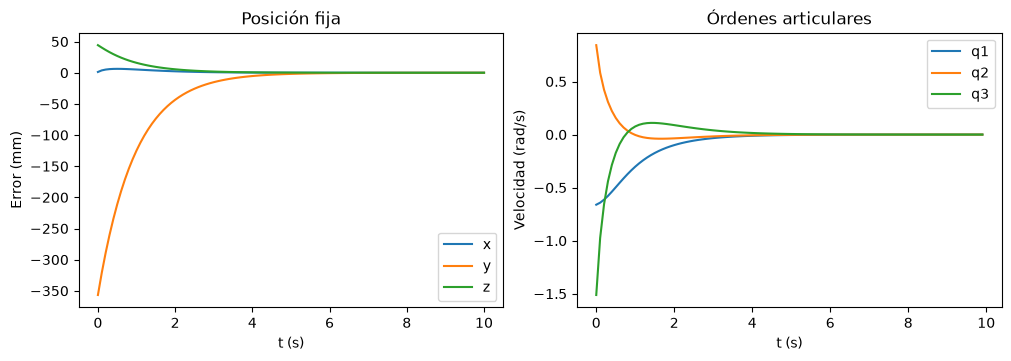

In [6]:
target = position([-0.3, 0.8, -1])
fixed = simulate_control([0.5, 0.6, -0.8], 10, 0.1, target)
t, actual, desired, errors, commands, sigma = fixed
print("Error inicial (m):", np.linalg.norm(errors[0]))
print("Error final (m):", np.linalg.norm(errors[-1]))
print("Máxima velocidad articular (rad/s):", np.abs(commands).max())
assert np.linalg.norm(errors[-1]) < 2e-5
assert sigma.min() > 0.01

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].plot(t, errors * 1000)
axes[0].set(xlabel="t (s)", ylabel="Error (mm)", title="Posición fija")
axes[0].legend(["x", "y", "z"])
axes[1].plot(t[:-1], commands)
axes[1].set(xlabel="t (s)", ylabel="Velocidad (rad/s)", title="Órdenes articulares")
axes[1].legend(["q1", "q2", "q3"])
plt.show()

## 4. Seguimiento y efecto del paso

Se usa la rama de codo negativa de la inversa inicial y se suma `[0.12,-0.08,0.10]` rad. Este desplazamiento crea un transitorio observable. El RMSE es la raíz de la media de la norma del error al cuadrado, no el promedio por eje.

Se informa tanto el intervalo completo como los últimos 10 s. Excluir el transitorio reduce la métrica; por eso siempre se declara la ventana.

Paso 0.1 s: RMSE total=0.008589 m; RMSE 10–20 s=0.000267 m
Paso 0.05 s: RMSE total=0.008479 m; RMSE 10–20 s=0.000133 m


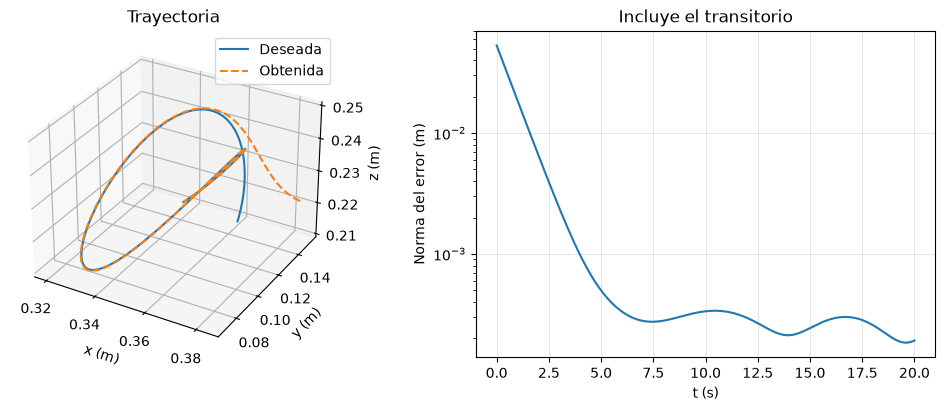

In [7]:
q_initial = inverse_position(reference(0)[0])[-1] + [0.12, -0.08, 0.10]
tracking = simulate_control(q_initial, 20, 0.1)
fine = simulate_control(q_initial, 20, 0.05)
tail_errors = []
for dt, result in [(0.1, tracking), (0.05, fine)]:
    t, actual, desired, errors, commands, sigma = result
    norms = np.linalg.norm(errors, axis=1)
    rmse = np.sqrt(np.mean(norms**2))
    tail_rmse = np.sqrt(np.mean(norms[t >= 10]**2))
    tail_errors.append(tail_rmse)
    print(f"Paso {dt} s: RMSE total={rmse:.6f} m; RMSE 10–20 s={tail_rmse:.6f} m")
    assert sigma.min() > 0.01
assert tail_errors[1] < 0.6 * tail_errors[0]

t, actual, desired, errors, commands, sigma = tracking
fig = plt.figure(figsize=(10, 4), layout="constrained")
ax = fig.add_subplot(121, projection="3d")
ax.plot(*desired.T, label="Deseada")
ax.plot(*actual.T, "--", label="Obtenida")
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", title="Trayectoria")
ax.legend()
ax = fig.add_subplot(122)
ax.semilogy(t, np.linalg.norm(errors, axis=1))
ax.set(xlabel="t (s)", ylabel="Norma del error (m)", title="Incluye el transitorio")
ax.grid(alpha=0.3)
plt.show()

## 5. Conservar también un caso que falla

La misma ley se inicia en la extensión horizontal con objetivo radial. La pseudoinversa no consigue iniciar el movimiento. Se comprueba que el error permanece en 3 cm; este resultado es una limitación, no una validación favorable.

In [8]:
stalled = simulate_control([0, 0, 0], 1, 0.1, np.array([0.50, 0, 0.04]))
error_norms = np.linalg.norm(stalled[3], axis=1)
assert np.allclose(error_norms, 0.03)
assert np.allclose(stalled[4], 0, atol=1e-12)
print("Errores en el caso singular (m):", error_norms)

Errores en el caso singular (m): [0.03 0.03 0.03 0.03 0.03 0.03 0.03 0.03 0.03 0.03 0.03]


## Lectura y ejercicio

El error final de posición fija debe estar cerca de 9.57e-6 m. El RMSE de seguimiento entre 10–20 s es aproximadamente 2.67e-4 m con paso 0.1 s y 1.33e-4 m con paso 0.05 s. Son resultados del modelo ideal y de estas condiciones iniciales.

Cambiar la ganancia o el paso exige observar simultáneamente error, velocidades y cercanía a singularidades. La convergencia continua no asegura estabilidad de cualquier discretización. Para revisar el experimento auxiliar con ruido: [datos sintéticos](../synthetic-data/README.md).